In [ ]:
import zipfile
import os

zip_files = [
    "Dataset1.zip",
    "Dataset2.zip",
    "Dataset3.zip",
    "Dataset4.zip",
    "Dataset5.zip",
    "Dataset6.zip"
]

os.makedirs("/content/all_datasets", exist_ok=True)

for zip_file in zip_files:
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall("/content/all_datasets")

print("All datasets extracted.")

FileNotFoundError: [Errno 2] No such file or directory: 'Dataset1.zip'

In [ ]:
#Inspect Dataset Structure
import os

for root, dirs, files in os.walk("/content/all_datasets"):
    print(root, len(files))

In [ ]:
#Create One Clean Dataset
import os

classes = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

base_dir = "/content/waste_dataset"

for cls in classes:
    os.makedirs(os.path.join(base_dir, cls), exist_ok=True)

print("Folders created.")

In [ ]:
#Remove Duplicate Images
import os
import hashlib
import shutil

source_dir = "/content/all_datasets"
clean_dir = "/content/waste_dataset"

seen = set()
duplicates = 0
copied = 0

valid_extensions = (".jpg", ".jpeg", ".png", ".webp")

for root, dirs, files in os.walk(source_dir):

    for file in files:

        if not file.lower().endswith(valid_extensions):
            continue

        file_path = os.path.join(root, file)

        try:
            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            if file_hash in seen:
                duplicates += 1
                continue

            seen.add(file_hash)

        except:
            continue

        # Find class from folder name
        class_name = os.path.basename(root).lower()

        if class_name not in classes:
            continue

        destination = os.path.join(
            clean_dir,
            class_name,
            file
        )

        # Avoid filename collision
        if os.path.exists(destination):
            name, ext = os.path.splitext(file)
            destination = os.path.join(
                clean_dir,
                class_name,
                f"{name}_{copied}{ext}"
            )

        shutil.copy2(file_path, destination)
        copied += 1

print("Images copied:", copied)
print("Duplicates removed:", duplicates)

In [ ]:
#Check Number of Images Per Class
import os

for cls in classes:

    folder = os.path.join(clean_dir, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ])

    print(cls, ":", count)

In [ ]:
#Dataset EDA
import matplotlib.pyplot as plt

counts = []

for cls in classes:
    folder = os.path.join(clean_dir, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ])

    counts.append(count)

plt.figure(figsize=(12,6))
plt.bar(classes, counts)
plt.xticks(rotation=45)
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Waste Dataset Class Distribution")
plt.show()

In [ ]:
#Display Sample Images
import random
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15,10))

for i, cls in enumerate(classes):

    folder = os.path.join(clean_dir, cls)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    image_file = random.choice(images)

    img = Image.open(os.path.join(folder, image_file))

    plt.subplot(3, 4, i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

70% Training
15% Validation
15% Testing

For example :
1000 images
│
├── 700 → Training
├── 150 → Validation
└── 150 → Testing

In [ ]:
!pip install split-folders

In [ ]:
#Train/Validation/Test Split
import splitfolders

splitfolders.ratio(
    "/content/waste_dataset",
    output="/content/split_dataset",
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

Image Preprocessing
Use:
Image Size = 224 × 224
Batch Size = 32

In [ ]:
#Image Preprocessing
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
#Create Data Generators
train_generator = train_datagen.flow_from_directory(
    "/content/split_dataset/train",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

val_generator = val_datagen.flow_from_directory(
    "/content/split_dataset/val",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

test_generator = test_datagen.flow_from_directory(
    "/content/split_dataset/test",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Model 1: CNN
Your first model should be your custom CNN.
Architecture:
Input Image
->
224 × 224 × 3
->
Conv2D
->
MaxPooling
->
Conv2D
->
MaxPooling
->
Conv2D
->
MaxPooling
->
Flatten
->
Dense
->
Dropout
->
12 Classes

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn = models.Sequential([

    layers.Conv2D(32, (3,3), activation="relu",
                  input_shape=(224,224,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(12, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

In [ ]:
#Train CNN
history_cnn = cnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

In [ ]:
cnn.save("/content/cnn_model.keras")

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os
import shutil

os.makedirs(
    "/content/drive/MyDrive/Waste_Classification",
    exist_ok=True
)

shutil.copy2(
    "/content/cnn_model.keras",
    "/content/drive/MyDrive/Waste_Classification/cnn_model.keras"
)

print("✅ CNN model saved safely to Google Drive!")

In [ ]:
import os

path = "/content/drive/MyDrive/Waste_Classification/cnn_model.keras"

print(os.path.exists(path))

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/cnn_model.keras"
)

test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

In [ ]:
#precision/recall/f1-score
import numpy as np
from sklearn.metrics import classification_report

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(test_generator.class_indices.keys())
    )
)

NameError: name 'test_generator' is not defined

In [ ]:
#confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_generator.class_indices.keys(),
    yticklabels=test_generator.class_indices.keys()
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")

plt.show()

NameError: name 'y_true' is not defined

In [ ]:
%whos

In [ ]:
#Accuracy graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

#Loss graph
plt.figure(figsize=(8,5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

Accuracy:
- Training accuracy increased from about 38% → 69%.
- Validation accuracy increased from about 49% → 72%.
- The validation accuracy is generally higher than training accuracy, which can happen when data augmentation is used during training.

Loss:
- Training loss decreased from about 1.82 → 0.95.
- Validation loss decreased from about 1.52 → 0.87.
- Both losses generally decrease, which indicates that the CNN is learning.


In [ ]:
#For your project, you should now calculate the final Test Accuracy and Test Loss using your unseen test dataset.
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/cnn_model.keras"
)

test_loss, test_accuracy = model.evaluate(
    test_generator
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

In [ ]:
#Test Accuracy graph
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.bar(
    ["Test Accuracy"],
    [test_accuracy * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("CNN Test Accuracy")
plt.ylim(0, 100)

plt.text(
    0,
    test_accuracy * 100 + 2,
    f"{test_accuracy * 100:.2f}%",
    ha="center"
)

plt.show()
#Test Loss graph
plt.figure(figsize=(7,5))

plt.bar(
    ["Test Loss"],
    [test_loss]
)

plt.ylabel("Loss")
plt.title("CNN Test Loss")

plt.text(
    0,
    test_loss + 0.02,
    f"{test_loss:.4f}",
    ha="center"
)

plt.show()

Your CNN test results are:
Metric	Result
Test Accuracy: 71.60%
Test Loss: 0.8915

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Final CNN performance From your classification report:

Metric Score:

Test Accuracy	 71.60%

Test Loss 	0.8915

Macro Precision 	0.74

Macro Recall	 0.68

Macro F1-Score	 0.70

Weighted Precision	 0.74

Weighted Recall 	0.72

Weighted F1-Score	 0.72

Test Images	 4,698



Best-performing classes Your CNN performs particularly well on:
- Clothes: F1 = 0.88
- Green-glass: F1 = 0.86
- Biological: F1 = 0.79
- Brown-glass: F1 = 0.76

Classes that need improvementThe weaker classes are:
- Trash: F1 = 0.53
- White-glass: F1 = 0.57
- Metal: F1 = 0.61
- Paper: F1 = 0.62
- Plastic: F1 = 0.66

In [ ]:
model.save("/content/cnn_model.keras")

print("✅ CNN model saved successfully")

In [ ]:
import os

print(os.path.exists("/content/cnn_model.keras"))

In [ ]:
import json

class_indices = train_generator.class_indices

print(class_indices)

In [ ]:
class_names = [
    None
] * len(class_indices)

for name, index in class_indices.items():
    class_names[index] = name

print(class_names)

In [ ]:
with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print("✅ Class names saved")

In [28]:
%%writefile /content/app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="SmartWaste AI",
    page_icon="♻️",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# CUSTOM CSS
# ============================================================

st.markdown("""
<style>

/* =========================================================
   MAIN BACKGROUND
========================================================= */

.stApp {

    background:
        radial-gradient(
            circle at 10% 10%,
            rgba(16,185,129,0.18),
            transparent 30%
        ),

        radial-gradient(
            circle at 90% 20%,
            rgba(34,197,94,0.14),
            transparent 28%
        ),

        radial-gradient(
            circle at 80% 90%,
            rgba(5,150,105,0.12),
            transparent 30%
        ),

        linear-gradient(
            135deg,
            #f0fdf4 0%,
            #f8fafc 45%,
            #ecfdf5 100%
        );

    min-height: 100vh;
}


/* =========================================================
   FLOATING ECO DECORATIONS
========================================================= */

.stApp::before {

    content: "♻️    🌿    🍃    ♻️    🌱    🍃";

    position: fixed;

    top: 8%;
    left: 3%;

    width: 100%;

    font-size: 55px;

    letter-spacing: 55px;

    opacity: 0.045;

    pointer-events: none;

    z-index: 0;

    transform: rotate(-8deg);
}


.stApp::after {

    content: "🌱     ♻️     🍃     🌿";

    position: fixed;

    bottom: 5%;
    right: 2%;

    font-size: 65px;

    letter-spacing: 45px;

    opacity: 0.04;

    pointer-events: none;

    z-index: 0;

    transform: rotate(8deg);
}


/* =========================================================
   MAIN CONTENT
========================================================= */

.block-container {

    position: relative;

    z-index: 1;

    padding-top: 2rem;

    padding-bottom: 3rem;

    max-width: 1400px;
}


/* =========================================================
   HERO SECTION
========================================================= */

.hero {

    padding: 40px;

    border-radius: 28px;

    background:
        linear-gradient(
            135deg,
            rgba(6,78,59,0.98),
            rgba(4,120,87,0.95),
            rgba(16,185,129,0.90)
        );

    color: white;

    margin-bottom: 28px;

    box-shadow:
        0 20px 50px rgba(4,120,87,0.22);

    border:
        1px solid rgba(255,255,255,0.18);

    position: relative;

    overflow: hidden;
}


.hero::after {

    content: "♻️";

    position: absolute;

    right: 45px;

    top: 5px;

    font-size: 130px;

    opacity: 0.10;

    transform: rotate(15deg);
}


.hero h1 {

    font-size: 46px;

    font-weight: 800;

    margin: 0;

    color: white;
}


.hero p {

    font-size: 18px;

    opacity: 0.92;

    margin-bottom: 5px;
}


/* =========================================================
   GLASS CARDS
========================================================= */

.card {

    background:
        rgba(255,255,255,0.84);

    backdrop-filter:
        blur(14px);

    -webkit-backdrop-filter:
        blur(14px);

    padding: 26px;

    border-radius: 22px;

    border:
        1px solid rgba(255,255,255,0.75);

    box-shadow:
        0 10px 35px rgba(15,23,42,0.07);

    margin-bottom: 20px;

    transition:
        transform 0.25s ease,
        box-shadow 0.25s ease;
}


.card:hover {

    transform:
        translateY(-4px);

    box-shadow:
        0 18px 45px rgba(15,23,42,0.12);
}


/* =========================================================
   KPI CARDS
========================================================= */

.kpi {

    background:
        rgba(255,255,255,0.90);

    backdrop-filter:
        blur(12px);

    padding: 25px;

    border-radius: 20px;

    border:
        1px solid rgba(255,255,255,0.8);

    box-shadow:
        0 8px 30px rgba(15,23,42,0.07);

    text-align: center;

    transition:
        transform 0.25s ease;
}


.kpi:hover {

    transform:
        translateY(-5px);
}


.kpi-value {

    font-size: 34px;

    font-weight: 800;

    color: #047857;
}


.kpi-label {

    color: #667085;

    font-size: 14px;

    margin-top: 6px;
}


/* =========================================================
   PREDICTION CARD
========================================================= */

.prediction {

    background:
        linear-gradient(
            135deg,
            rgba(236,253,245,0.96),
            rgba(209,250,229,0.92)
        );

    padding: 32px;

    border-radius: 24px;

    border:
        1px solid #a7f3d0;

    text-align: center;

    box-shadow:
        0 12px 35px rgba(5,150,105,0.12);
}


.prediction-label {

    font-size: 15px;

    color: #475467;
}


.prediction-class {

    font-size: 40px;

    font-weight: 800;

    color: #047857;

    margin: 8px 0;
}


.prediction-confidence {

    font-size: 21px;

    font-weight: 700;

    color: #065f46;
}


/* =========================================================
   CATEGORY BADGES
========================================================= */

.category {

    display: inline-block;

    padding: 9px 16px;

    margin: 5px;

    border-radius: 25px;

    background:
        rgba(236,253,245,0.90);

    color: #047857;

    border:
        1px solid #a7f3d0;

    font-weight: 600;

    transition:
        transform 0.2s ease,
        background 0.2s ease;
}


.category:hover {

    transform:
        translateY(-3px);

    background:
        #d1fae5;
}


/* =========================================================
   SIDEBAR
========================================================= */

section[data-testid="stSidebar"] {

    background:
        linear-gradient(
            180deg,
            #022c22,
            #064e3b,
            #065f46
        );
}


section[data-testid="stSidebar"] * {

    color: white;
}


/* =========================================================
   FILE UPLOADER
========================================================= */

[data-testid="stFileUploader"] {

    background:
        rgba(255,255,255,0.88);

    backdrop-filter:
        blur(10px);

    border-radius: 18px;

    padding: 12px;

    border:
        1px dashed #10b981;

    box-shadow:
        0 8px 25px rgba(15,23,42,0.06);
}


/* =========================================================
   BUTTONS
========================================================= */

.stButton > button {

    border-radius: 12px;

    border: none;

    background:
        linear-gradient(
            135deg,
            #047857,
            #10b981
        );

    color: white;

    font-weight: 700;

    padding: 10px 22px;

    box-shadow:
        0 5px 15px rgba(4,120,87,0.20);

    transition:
        transform 0.2s ease;
}


.stButton > button:hover {

    transform:
        translateY(-2px);

    box-shadow:
        0 8px 20px rgba(4,120,87,0.30);
}


/* =========================================================
   HEADINGS
========================================================= */

h1,
h2,
h3 {

    color: #172033;

    font-weight: 750;
}


/* =========================================================
   HIDE STREAMLIT DEFAULT ELEMENTS
========================================================= */

#MainMenu {

    visibility: hidden;
}


footer {

    visibility: hidden;
}

</style>
""", unsafe_allow_html=True)


# ============================================================
# LOAD CNN MODEL
# ============================================================

@st.cache_resource
def load_model():

    model = tf.keras.models.load_model(
        "/content/cnn_model.keras"
    )

    return model


model = load_model()


# ============================================================
# LOAD CLASS NAMES
# ============================================================

with open(
    "/content/class_names.json",
    "r"
) as file:

    loaded_classes = json.load(file)


# Handle either JSON list or dictionary

if isinstance(loaded_classes, dict):

    # Example:
    # {"battery": 0, "plastic": 8}

    class_names = [
        name
        for name, index
        in sorted(
            loaded_classes.items(),
            key=lambda x: x[1]
        )
    ]

else:

    class_names = loaded_classes


# ============================================================
# MODEL PERFORMANCE
# ============================================================

TEST_ACCURACY = 71.60

TEST_LOSS = 0.8915

PRECISION = 0.74

RECALL = 0.72

F1_SCORE = 0.72

TEST_IMAGES = 4698


# ============================================================
# CLASS-WISE F1 SCORE
# ============================================================

class_f1 = {

    "battery": 0.72,

    "biological": 0.79,

    "brown-glass": 0.76,

    "cardboard": 0.67,

    "clothes": 0.88,

    "green-glass": 0.86,

    "metal": 0.61,

    "paper": 0.62,

    "plastic": 0.66,

    "shoes": 0.73,

    "trash": 0.53,

    "white-glass": 0.57
}


# ============================================================
# DISPOSAL RECOMMENDATIONS
# ============================================================

recommendations = {

    "battery":
        "🔋 Dispose of batteries at an authorized e-waste collection point.",

    "biological":
        "🌱 Place biological waste in the organic or composting waste bin.",

    "brown-glass":
        "🍾 Place brown glass in the glass recycling bin.",

    "cardboard":
        "📦 Flatten cardboard and place it in the paper/cardboard recycling bin.",

    "clothes":
        "👕 Donate reusable clothes or send them for textile recycling.",

    "green-glass":
        "🍾 Place green glass in the glass recycling bin.",

    "metal":
        "🔩 Place metal in the metal recycling collection.",

    "paper":
        "📄 Place clean paper in the paper recycling bin.",

    "plastic":
        "♻️ Place recyclable plastic in the plastic recycling bin.",

    "shoes":
        "👟 Donate reusable shoes or send them to textile/shoe recycling.",

    "trash":
        "🗑️ Place this item in the general waste bin.",

    "white-glass":
        "🥛 Place white glass in the glass recycling bin."
}


# ============================================================
# SESSION HISTORY
# ============================================================

if "history" not in st.session_state:

    st.session_state.history = []


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.markdown(
    "## ♻️ SmartWaste AI"
)

st.sidebar.caption(
    "Smart Campus Waste Management"
)

st.sidebar.markdown("---")

page = st.sidebar.radio(

    "Navigation",

    [
        "🏠 Dashboard",
        "🔍 Classify Waste",
        "📊 Analytics",
        "ℹ️ About"
    ]
)

st.sidebar.markdown("---")

st.sidebar.markdown(
    "### 🧠 Model Information"
)

st.sidebar.write(
    "Model: CNN"
)

st.sidebar.write(
    "Input: 224 × 224"
)

st.sidebar.write(
    "Categories: 12"
)

st.sidebar.write(
    "Test Accuracy: 71.60%"
)

st.sidebar.markdown("---")

st.sidebar.caption(
    "AI-powered waste classification"
)


# ============================================================
# DASHBOARD
# ============================================================

if page == "🏠 Dashboard":

    st.markdown(
        """
        <div class="hero">

        <h1>♻️ SmartWaste AI</h1>

        <p>
        AI-Powered Smart Campus Waste Management
        </p>

        <p>
        Automatically classify waste using
        Convolutional Neural Networks and promote
        smarter waste segregation.
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # KPI CARDS
    # --------------------------------------------------------

    col1, col2, col3, col4 = st.columns(4)


    with col1:

        st.markdown(
            """
            <div class="kpi">

            <div class="kpi-value">
            71.60%
            </div>

            <div class="kpi-label">
            Test Accuracy
            </div>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col2:

        st.markdown(
            """
            <div class="kpi">

            <div class="kpi-value">
            0.72
            </div>

            <div class="kpi-label">
            Weighted F1 Score
            </div>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col3:

        st.markdown(
            """
            <div class="kpi">

            <div class="kpi-value">
            4,698
            </div>

            <div class="kpi-label">
            Test Images
            </div>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col4:

        st.markdown(
            """
            <div class="kpi">

            <div class="kpi-value">
            12
            </div>

            <div class="kpi-label">
            Waste Categories
            </div>

            </div>
            """,
            unsafe_allow_html=True
        )


    st.markdown("<br>", unsafe_allow_html=True)


    # --------------------------------------------------------
    # PROJECT OVERVIEW
    # --------------------------------------------------------

    col1, col2 = st.columns([1.5, 1])


    with col1:

        st.markdown(
            """
            <div class="card">

            <h2>🌍 Smart Waste Management</h2>

            <p>
            Improper waste segregation is a major challenge
            in educational campuses. SmartWaste AI uses
            computer vision and deep learning to identify
            waste categories from images.
            </p>

            <p>
            The system helps users understand how waste
            should be categorized and provides a recommended
            disposal method.
            </p>

            </div>
            """,
            unsafe_allow_html=True
        )


    with col2:

        st.markdown(
            """
            <div class="card">

            <h3>🚀 Project Pipeline</h3>

            <p>📷 Image Input</p>

            <p>⬇️</p>

            <p>🧠 CNN Processing</p>

            <p>⬇️</p>

            <p>🎯 Classification</p>

            <p>⬇️</p>

            <p>♻️ Disposal Recommendation</p>

            </div>
            """,
            unsafe_allow_html=True
        )


    # --------------------------------------------------------
    # CATEGORIES
    # --------------------------------------------------------

    st.markdown(
        "### 🗂️ Supported Waste Categories"
    )

    category_html = ""

    for category in class_names:

        category_html += (
            f'<span class="category">'
            f'{category}'
            f'</span>'
        )

    st.markdown(
        category_html,
        unsafe_allow_html=True
    )


    st.markdown("<br>", unsafe_allow_html=True)


    # --------------------------------------------------------
    # MODEL SUMMARY
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h3>🧠 CNN Model Summary</h3>

        <p>
        The trained CNN receives an image of size
        <strong>224 × 224 pixels</strong> and classifies
        it into one of <strong>12 waste categories</strong>.
        </p>

        <p>
        The current model achieved a test accuracy of
        <strong>71.60%</strong> and weighted F1-score of
        <strong>0.72</strong>.
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


# ============================================================
# CLASSIFY WASTE
# ============================================================

elif page == "🔍 Classify Waste":

    st.markdown(
        """
        <div class="hero">

        <h1>🔍 Waste Classification</h1>

        <p>
        Upload a waste image or capture one using your camera.
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # INPUT
    # --------------------------------------------------------

    upload_col, camera_col = st.columns(2)


    with upload_col:

        uploaded_file = st.file_uploader(

            "📁 Upload Waste Image",

            type=[
                "jpg",
                "jpeg",
                "png"
            ]
        )


    with camera_col:

        camera_file = st.camera_input(
            "📷 Capture Waste Image"
        )


    # Select input

    if uploaded_file is not None:

        image_file = uploaded_file

    elif camera_file is not None:

        image_file = camera_file

    else:

        image_file = None


    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    if image_file is not None:

        image = Image.open(
            image_file
        ).convert("RGB")


        st.divider()


        image_col, result_col = st.columns(
            [1, 1]
        )


        # ----------------------------------------------------
        # INPUT IMAGE
        # ----------------------------------------------------

        with image_col:

            st.markdown(
                "### 📷 Input Image"
            )

            st.image(
                image,
                use_container_width=True
            )


        # ----------------------------------------------------
        # PREPROCESSING
        # ----------------------------------------------------

        resized_image = image.resize(
            (224, 224)
        )


        image_array = np.array(
            resized_image,
            dtype=np.float32
        )


        # IMPORTANT:
        # Same normalization used by the application

        image_array = image_array / 255.0


        image_array = np.expand_dims(
            image_array,
            axis=0
        )


        # ----------------------------------------------------
        # CNN PREDICTION
        # ----------------------------------------------------

        prediction = model.predict(
            image_array,
            verbose=0
        )[0]


        predicted_index = int(
            np.argmax(prediction)
        )


        predicted_class = class_names[
            predicted_index
        ]


        confidence = float(
            prediction[predicted_index] * 100
        )


        # ----------------------------------------------------
        # RESULT
        # ----------------------------------------------------

        with result_col:

            st.markdown(
                "### 🤖 AI Prediction"
            )


            st.markdown(
                f"""
                <div class="prediction">

                <div class="prediction-label">
                Predicted Waste Category
                </div>

                <div class="prediction-class">
                ♻️ {predicted_class}
                </div>

                <div class="prediction-confidence">
                {confidence:.2f}% Confidence
                </div>

                </div>
                """,
                unsafe_allow_html=True
            )


            st.progress(
                float(
                    prediction[predicted_index]
                )
            )


        st.markdown("<br>", unsafe_allow_html=True)


        # ----------------------------------------------------
        # CONFIDENCE MESSAGE
        # ----------------------------------------------------

        if confidence >= 80:

            st.success(
                "🟢 High-confidence prediction"
            )

        elif confidence >= 60:

            st.info(
                "🟡 Moderate-confidence prediction"
            )

        else:

            st.warning(
                "🔴 Low-confidence prediction. "
                "Try a clearer image with the waste "
                "item centered and well illuminated."
            )


        # ----------------------------------------------------
        # DISPOSAL RECOMMENDATION
        # ----------------------------------------------------

        st.markdown(
            """
            <div class="card">

            <h3>♻️ Recommended Disposal</h3>

            """,
            unsafe_allow_html=True
        )


        st.write(
            recommendations.get(
                predicted_class,
                "Dispose of the item appropriately."
            )
        )


        st.markdown(
            "</div>",
            unsafe_allow_html=True
        )


        # ----------------------------------------------------
        # TOP 3 PREDICTIONS
        # ----------------------------------------------------

        st.markdown(
            "### 📊 Top 3 Predictions"
        )


        top_indices = np.argsort(
            prediction
        )[-3:][::-1]


        top_data = []


        for rank, index in enumerate(
            top_indices,
            start=1
        ):

            top_data.append({

                "Rank":
                    rank,

                "Category":
                    class_names[index],

                "Confidence":
                    round(
                        float(
                            prediction[index] * 100
                        ),
                        2
                    )
            })


        top_df = pd.DataFrame(
            top_data
        )


        # Bar chart

        chart_df = top_df[
            [
                "Category",
                "Confidence"
            ]
        ].set_index(
            "Category"
        )


        st.bar_chart(
            chart_df
        )


        st.dataframe(
            top_df,
            use_container_width=True,
            hide_index=True
        )


        # ----------------------------------------------------
        # SAVE SESSION HISTORY
        # ----------------------------------------------------

        st.session_state.history.append({

            "Prediction":
                predicted_class,

            "Confidence":
                round(
                    confidence,
                    2
                )
        })


# ============================================================
# ANALYTICS
# ============================================================

elif page == "📊 Analytics":

    st.markdown(
        """
        <div class="hero">

        <h1>📊 Model Analytics</h1>

        <p>
        Performance analysis of the trained CNN model
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # KPI
    # --------------------------------------------------------

    c1, c2, c3, c4 = st.columns(4)


    with c1:

        st.metric(
            "Test Accuracy",
            "71.60%"
        )


    with c2:

        st.metric(
            "Test Loss",
            "0.8915"
        )


    with c3:

        st.metric(
            "Precision",
            "0.74"
        )


    with c4:

        st.metric(
            "Recall",
            "0.72"
        )


    st.divider()


    # --------------------------------------------------------
    # F1 SCORE CHART
    # --------------------------------------------------------

    st.subheader(
        "📈 F1 Score by Waste Category"
    )


    f1_df = pd.DataFrame({

        "Category":
            list(class_f1.keys()),

        "F1 Score":
            list(class_f1.values())
    })


    st.bar_chart(
        f1_df.set_index(
            "Category"
        )
    )


    # --------------------------------------------------------
    # MODEL METRICS TABLE
    # --------------------------------------------------------

    st.subheader(
        "📋 Overall Model Evaluation"
    )


    metrics_df = pd.DataFrame({

        "Metric": [

            "Test Accuracy",

            "Test Loss",

            "Precision",

            "Recall",

            "Weighted F1 Score"

        ],

        "Value": [

            "71.60%",

            "0.8915",

            "0.74",

            "0.72",

            "0.72"

        ]
    })


    st.dataframe(

        metrics_df,

        use_container_width=True,

        hide_index=True
    )


    # --------------------------------------------------------
    # CLASS PERFORMANCE TABLE
    # --------------------------------------------------------

    st.subheader(
        "🗂️ Class-wise F1 Performance"
    )


    class_df = pd.DataFrame({

        "Waste Category":
            list(class_f1.keys()),

        "F1 Score":
            list(class_f1.values())
    })


    st.dataframe(

        class_df,

        use_container_width=True,

        hide_index=True
    )


    # --------------------------------------------------------
    # SESSION PREDICTION HISTORY
    # --------------------------------------------------------

    st.subheader(
        "🕒 Current Session Predictions"
    )


    if len(
        st.session_state.history
    ) > 0:

        history_df = pd.DataFrame(
            st.session_state.history
        )


        st.dataframe(

            history_df,

            use_container_width=True,

            hide_index=True
        )

    else:

        st.info(
            "No predictions have been made "
            "during this session."
        )


# ============================================================
# ABOUT
# ============================================================

elif page == "ℹ️ About":

    st.markdown(
        """
        <div class="hero">

        <h1>ℹ️ About SmartWaste AI</h1>

        <p>
        Waste Classification for Smart Campus Waste Management
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # PROBLEM
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h2>🌍 Real-World Problem</h2>

        <p>
        Improper waste segregation is a major environmental
        and operational challenge in educational campuses.
        Different waste materials require different disposal
        and recycling methods.
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # SOLUTION
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h2>💡 Proposed Solution</h2>

        <p>
        SmartWaste AI uses a Convolutional Neural Network
        to automatically classify waste from an image.
        The application then provides a disposal recommendation
        to the user.
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # TECHNOLOGY
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h2>🛠️ Technologies Used</h2>

        <p>🐍 Python</p>

        <p>🧠 TensorFlow / Keras</p>

        <p>👁️ Convolutional Neural Network</p>

        <p>📊 NumPy / Pandas / Matplotlib</p>

        <p>🌐 Streamlit</p>

        <p>🖼️ PIL</p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # PIPELINE
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h2>🔄 Project Workflow</h2>

        <p>
        Data Collection
        →
        Data Cleaning
        →
        EDA
        →
        Train/Validation/Test Split
        →
        CNN Training
        →
        Evaluation
        →
        Best Model
        →
        Streamlit Application
        →
        New Image
        →
        Prediction
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # PERFORMANCE
    # --------------------------------------------------------

    st.markdown(
        """
        <div class="card">

        <h2>🏆 Current Model Performance</h2>

        <p>
        Test Accuracy:
        <strong>71.60%</strong>
        </p>

        <p>
        Weighted F1 Score:
        <strong>0.72</strong>
        </p>

        <p>
        Test Images:
        <strong>4,698</strong>
        </p>

        <p>
        Waste Categories:
        <strong>12</strong>
        </p>

        </div>
        """,
        unsafe_allow_html=True
    )


    # --------------------------------------------------------
    # CATEGORIES
    # --------------------------------------------------------

    st.subheader(
        "🗂️ Supported Categories"
    )


    category_html = ""


    for category in class_names:

        category_html += (

            f'<span class="category">'
            f'{category}'
            f'</span>'

        )


    st.markdown(

        category_html,

        unsafe_allow_html=True
    )


    st.markdown("---")


    st.caption(
        "SmartWaste AI | Deep Learning Project | CNN"
    )

Writing /content/app.py


In [ ]:
import os

print(os.path.exists("/content/app.py"))

In [ ]:
print(os.listdir("/content"))

In [ ]:
!streamlit run /content/app.py --server.port 8501

However, this command will keep the cell running because Streamlit is a server.
For Colab, it's better to start it in the background:

In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(8501)

In [ ]:
!pkill -f "streamlit run" || true

In [ ]:
!streamlit run /content/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

In [ ]:
!ps aux | grep streamlit

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

In [ ]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image

model = tf.keras.models.load_model(
    "/content/cnn_model.keras"
)

# Get exact class order from your generator
class_names = list(train_generator.class_indices.keys())

print("Class order:")
print(class_names)

In [ ]:
plastic_folder = "/content/split_dataset/test/plastic"

plastic_images = [
    f for f in os.listdir(plastic_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Plastic test images:", len(plastic_images))
print("Example:", plastic_images[0])

In [ ]:
image_path = os.path.join(
    plastic_folder,
    plastic_images[0]
)

image = Image.open(image_path).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image) / 255.0
image_array = np.expand_dims(image_array, axis=0)

prediction = model.predict(
    image_array,
    verbose=0
)[0]

top_indices = np.argsort(prediction)[-3:][::-1]

for i in top_indices:
    print(
        class_names[i],
        f"{prediction[i] * 100:.2f}%"
    )

In [ ]:
rescale=1./255

In [ ]:
print(train_generator.class_indices)

In [ ]:
!pkill -f "streamlit run" || true

In [ ]:
!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-use1c2-3rntpwrjz7mib-c.us-east1-2.prod.colab.dev


In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!which streamlit

/usr/local/bin/streamlit


In [ ]:
!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-use1c2-3rntpwrjz7mib-c.us-east1-2.prod.colab.dev


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

/content/cnn_model.keras
/content/drive/MyDrive/Waste_Classification/cnn_model.keras


In [ ]:
!find /content -type f \( -name "*.keras" -o -name "*.h5" \)

/content/cnn_model.keras
/content/drive/MyDrive/Waste_Classification/cnn_model.keras


In [ ]:
!find /content -type f -name "class_names.json"

/content/class_names.json


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!find /content/drive -type f \( -name "*.keras" -o -name "*.h5" \)

/content/drive/MyDrive/Waste_Classification/cnn_model.keras


In [ ]:
!find /content/drive -type f -name "class_names.json"

In [ ]:
import os

print(os.path.exists("/content/cnn_model.keras"))

True


In [ ]:
import os

print("Searching for CNN model...\n")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

Searching for CNN model...

/content/cnn_model.keras
/content/drive/MyDrive/Waste_Classification/cnn_model.keras


In [ ]:
import os

print("Searching Google Drive for CNN model...\n")

found = False

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))
            found = True

if not found:
    print("❌ No .keras or .h5 model found in Google Drive")

Searching Google Drive for CNN model...

/content/drive/MyDrive/Waste_Classification/cnn_model.keras


In [ ]:
import shutil

shutil.copy(
    "/content/drive/MyDrive/Waste_Classification/cnn_model.keras",
    "/content/cnn_model.keras"
)

print("CNN model copied successfully!")

CNN model copied successfully!


In [ ]:
import os

print(
    "Model exists:",
    os.path.exists("/content/cnn_model.keras")
)

Model exists: True


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "class_names.json":
            print(os.path.join(root, file))

In [ ]:
import os

# Search everywhere in Drive
matches = []

for root, dirs, files in os.walk("/content/drive"):
    for file in files:
        if file.lower() == "class_names.json":
            matches.append(os.path.join(root, file))

print("Found files:")

if matches:
    for path in matches:
        print(path)
else:
    print("❌ class_names.json not found")

Found files:
❌ class_names.json not found


In [ ]:
import json

class_names = {
    "battery": 0,
    "biological": 1,
    "brown-glass": 2,
    "cardboard": 3,
    "clothes": 4,
    "green-glass": 5,
    "metal": 6,
    "paper": 7,
    "plastic": 8,
    "shoes": 9,
    "trash": 10,
    "white-glass": 11
}

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print("class_names.json created successfully!")

class_names.json created successfully!


In [ ]:
import os

print("CNN model:",
      os.path.exists("/content/cnn_model.keras"))

print("Class names:",
      os.path.exists("/content/class_names.json"))

CNN model: True
Class names: True


In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image
import os

model = tf.keras.models.load_model(
    "/content/cnn_model.keras"
)

class_names = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

print("Model input shape:", model.input_shape)
print("Number of classes:", len(class_names))

In [ ]:
import os

test_path = "/content/split_dataset/test"

for category in os.listdir(test_path):

    folder = os.path.join(test_path, category)

    if os.path.isdir(folder):

        images = [
            x for x in os.listdir(folder)
            if x.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        if images:

            print(
                "Category:",
                category,
                "| Image:",
                images[0]
            )

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if os.path.basename(root).lower() == "clothes":
        print(root)

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import os

found = []

for root, dirs, files in os.walk("/content"):
    if "clothes" in [d.lower() for d in dirs]:
        path = os.path.join(root, "clothes")
        found.append(path)

print("Clothes folders found:")

for path in found:
    print(path)

if not found:
    print("❌ No clothes folder found in /content")

In [ ]:
import os

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "clothes" in [d.lower() for d in dirs]:
        path = os.path.join(root, "clothes")
        found.append(path)

print("Clothes folders in Google Drive:")

for path in found:
    print(path)

if not found:
    print("❌ No clothes folder found in Google Drive")

In [ ]:
import os

print("CONTENT:")
for x in os.listdir("/content"):
    print(x)

In [ ]:
import os

path = "/content/drive/MyDrive/Waste_Classification"

print("Files and folders:")
for item in os.listdir(path):
    print(item)

In [ ]:
import os

path = "/content/drive/MyDrive/Waste_Classification"

for root, dirs, files in os.walk(path):
    print(root)

In [ ]:
import os

classes = {
    "battery", "biological", "brown-glass", "cardboard",
    "clothes", "green-glass", "metal", "paper",
    "plastic", "shoes", "trash", "white-glass"
}

print("Searching Google Drive...\n")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    found = classes.intersection(
        d.lower() for d in dirs
    )

    if len(found) >= 3:
        print(root)
        print("Classes found:", sorted(found))
        print()

In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".zip"):
            print(os.path.join(root, file))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

print("My Drive:")
for item in os.listdir("/content/drive/MyDrive"):
    print(item)

In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/Waste management Dataset.zip"
extract_path = "/content/all_datasets"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")

In [ ]:
import os

for root, dirs, files in os.walk("/content/all_datasets"):
    level = root.replace("/content/all_datasets", "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

In [ ]:
import os

dataset_path = "/content/all_datasets/Waste management Dataset"

print("Datasets/Folders found:\n")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)

    if os.path.isdir(full_path):
        print("📁", item)

In [ ]:
import os

dataset_path = "/content/all_datasets/Waste management Dataset"

for dataset in os.listdir(dataset_path):

    dataset_folder = os.path.join(dataset_path, dataset)

    if os.path.isdir(dataset_folder):

        print("\n==============================")
        print("DATASET:", dataset)
        print("==============================")

        for item in os.listdir(dataset_folder):

            if os.path.isdir(os.path.join(dataset_folder, item)):
                print("  📁", item)

In [ ]:
import os

base = "/content/all_datasets"

for root, dirs, files in os.walk(base):
    print("\n📂", root)

    if dirs:
        print("   Folders:")
        for d in dirs:
            print("     -", repr(d))

    if files:
        print("   Files:")
        for f in files[:10]:
            print("     -", repr(f))

In [ ]:
import os
import zipfile

base_path = "/content/all_datasets/Waste management Dataset"
extract_base = "/content/extracted_datasets"

os.makedirs(extract_base, exist_ok=True)

for file in sorted(os.listdir(base_path)):
    if file.endswith(".zip") and not file.startswith("__"):

        zip_path = os.path.join(base_path, file)

        dataset_name = os.path.splitext(file)[0]
        extract_path = os.path.join(extract_base, dataset_name)

        os.makedirs(extract_path, exist_ok=True)

        print("Extracting:", file)

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_path)

print("\n✅ All 6 datasets extracted!")

In [ ]:
import os

base = "/content/extracted_datasets"

for dataset in sorted(os.listdir(base)):

    dataset_path = os.path.join(base, dataset)

    if not os.path.isdir(dataset_path):
        continue

    print("\n" + "=" * 50)
    print("📦", dataset)
    print("=" * 50)

    for root, dirs, files in os.walk(dataset_path):

        # Show folders only up to 2 levels deep
        level = root.replace(dataset_path, "").count(os.sep)

        if level <= 2:
            for d in sorted(dirs):
                print("  📁", d)

In [ ]:
import os
import shutil
import hashlib
from PIL import Image

# ============================================================
# PATHS
# ============================================================

SOURCE = "/content/extracted_datasets"
OUTPUT = "/content/Waste_Dataset_Clean"

# ============================================================
# FINAL 12 CLASSES
# ============================================================

classes = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

# Create output folders
for cls in classes:
    os.makedirs(os.path.join(OUTPUT, cls), exist_ok=True)

# ============================================================
# FOLDER MAPPING
# ============================================================

class_mapping = {
    "battery": "battery",

    "biological": "biological",
    "Food Organics": "biological",
    "Vegetation": "biological",

    "brown-glass": "brown-glass",

    "cardboard": "cardboard",
    "Cardboard": "cardboard",

    "clothes": "clothes",
    "Textile Trash": "clothes",

    "green-glass": "green-glass",

    "metal": "metal",
    "Metal": "metal",

    "paper": "paper",
    "Paper": "paper",

    "plastic": "plastic",
    "Plastic": "plastic",

    "shoes": "shoes",

    "trash": "trash",
    "Miscellaneous Trash": "trash",

    "white-glass": "white-glass"
}

# ============================================================
# IMAGE EXTENSIONS
# ============================================================

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# ============================================================
# DUPLICATE TRACKING
# ============================================================

hashes = set()

total_copied = 0
total_duplicates = 0
total_corrupt = 0
total_ignored = 0

# ============================================================
# PROCESS DATASETS
# ============================================================

for dataset in sorted(os.listdir(SOURCE)):

    dataset_path = os.path.join(SOURCE, dataset)

    if not os.path.isdir(dataset_path):
        continue

    print("\nProcessing:", dataset)

    # Walk recursively because some datasets have nested folders
    for root, dirs, files in os.walk(dataset_path):

        # Ignore Mac metadata
        dirs[:] = [
            d for d in dirs
            if d != "__MACOSX"
        ]

        # Check whether current folder is a recognized class
        folder_name = os.path.basename(root)

        if folder_name not in class_mapping:
            continue

        target_class = class_mapping[folder_name]

        for file in files:

            ext = os.path.splitext(file)[1].lower()

            if ext not in image_extensions:
                continue

            source_file = os.path.join(root, file)

            # ------------------------------------------------
            # Check image validity
            # ------------------------------------------------

            try:
                with Image.open(source_file) as img:
                    img.verify()

            except Exception:
                total_corrupt += 1
                continue

            # ------------------------------------------------
            # Calculate SHA-256
            # ------------------------------------------------

            try:
                sha256 = hashlib.sha256()

                with open(source_file, "rb") as f:
                    for chunk in iter(lambda: f.read(1024 * 1024), b""):
                        sha256.update(chunk)

                file_hash = sha256.hexdigest()

            except Exception:
                total_corrupt += 1
                continue

            # ------------------------------------------------
            # Remove exact duplicates
            # ------------------------------------------------

            if file_hash in hashes:
                total_duplicates += 1
                continue

            hashes.add(file_hash)

            # ------------------------------------------------
            # Create unique filename
            # ------------------------------------------------

            new_name = (
                f"{dataset}_"
                f"{total_copied:08d}_"
                f"{file}"
            )

            destination = os.path.join(
                OUTPUT,
                target_class,
                new_name
            )

            shutil.copy2(source_file, destination)

            total_copied += 1


# ============================================================
# SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("CLEANING COMPLETE")
print("=" * 60)

print("Images copied       :", total_copied)
print("Duplicates removed  :", total_duplicates)
print("Corrupt files       :", total_corrupt)
print("Output folder       :", OUTPUT)

In [ ]:
import os

print("\nFINAL CLASS COUNTS")
print("=" * 40)

total = 0

for cls in classes:

    folder = os.path.join(OUTPUT, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ])

    print(f"{cls:15s} : {count}")

    total += count

print("=" * 40)
print("TOTAL IMAGES:", total)

In [ ]:
import os

dataset6 = "/content/extracted_datasets/Dataset6"

print("DATASET6 STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(dataset6):

    # Ignore Mac metadata
    dirs[:] = [d for d in dirs if d != "__MACOSX"]

    image_count = sum(
        1 for f in files
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    )

    if image_count > 0:
        print(f"{root}")
        print(f"   Images: {image_count}")

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

# ============================================================
# PATHS
# ============================================================

SOURCE = "/content/Waste_Dataset_Clean"
OUTPUT = "/content/Waste_Dataset_Split"

# ============================================================
# CLASSES
# ============================================================

classes = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

# ============================================================
# CREATE TRAIN / VALIDATION / TEST FOLDERS
# ============================================================

for split in ["train", "validation", "test"]:
    for cls in classes:
        os.makedirs(
            os.path.join(OUTPUT, split, cls),
            exist_ok=True
        )

# ============================================================
# SPLIT DATA
# ============================================================

for cls in classes:

    class_folder = os.path.join(SOURCE, cls)

    images = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    # First: 70% train, 30% temporary
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # Second: temporary -> 15% validation + 15% test
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=42
    )

    print(
        f"{cls:15s} "
        f"Train: {len(train_images):5d} | "
        f"Val: {len(val_images):5d} | "
        f"Test: {len(test_images):5d}"
    )

    # ========================================================
    # COPY FILES
    # ========================================================

    for filename in train_images:

        src = os.path.join(class_folder, filename)
        dst = os.path.join(
            OUTPUT, "train", cls, filename
        )

        shutil.copy2(src, dst)

    for filename in val_images:

        src = os.path.join(class_folder, filename)
        dst = os.path.join(
            OUTPUT, "validation", cls, filename
        )

        shutil.copy2(src, dst)

    for filename in test_images:

        src = os.path.join(class_folder, filename)
        dst = os.path.join(
            OUTPUT, "test", cls, filename
        )

        shutil.copy2(src, dst)


print("\n" + "=" * 60)
print("✅ DATASET SPLIT COMPLETE")
print("=" * 60)
print("Train      : 70%")
print("Validation : 15%")
print("Test       : 15%")
print("Location   :", OUTPUT)

In [ ]:
import os
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

train_path = "/content/Waste_Dataset_Split/train"

classes = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

# Get training labels
y_train = []

for index, cls in enumerate(classes):
    folder = os.path.join(train_path, cls)

    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ])

    y_train.extend([index] * count)

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=np.array(y_train)
)

class_weights = {
    i: float(weights[i])
    for i in range(len(classes))
}

print("CLASS WEIGHTS")
print("=" * 45)

for i, cls in enumerate(classes):
    print(f"{cls:15s} : {class_weights[i]:.4f}")

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

In [ ]:
import os

print("Model:", os.path.exists("/content/cnn_model.keras"))
print("Classes:", os.path.exists("/content/class_names.json"))
print("App:", os.path.exists("/content/app.py"))

Model: True
Classes: True
App: True


In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-use1c2-3rntpwrjz7mib-c.us-east1-2.prod.colab.dev


In [ ]:
import numpy as np
from PIL import Image

def predict_image(image, model, class_names):

    # Convert to RGB
    image = image.convert("RGB")

    # Resize exactly like training
    image = image.resize((224, 224))

    # Convert to numpy
    img_array = np.array(image, dtype=np.float32)

    # Normalize
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    predictions = model.predict(img_array, verbose=0)[0]

    # Best prediction
    predicted_index = int(np.argmax(predictions))
    confidence = float(predictions[predicted_index])

    predicted_class = class_names[predicted_index]

    # Top 3
    top_indices = np.argsort(predictions)[::-1][:3]

    top_predictions = [
        (class_names[i], float(predictions[i]))
        for i in top_indices
    ]

    return predicted_class, confidence, top_predictions

In [ ]:
class_names = [
    "battery",
    "biological",
    "brown-glass",
    "cardboard",
    "clothes",
    "green-glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash",
    "white-glass"
]

In [ ]:
import tensorflow as tf
import json
import numpy as np
from PIL import Image
import os

# ==========================================
# LOAD MODEL
# ==========================================

model = tf.keras.models.load_model("/content/cnn_model.keras")

# ==========================================
# LOAD CLASS MAPPING
# ==========================================

with open("/content/class_names.json", "r") as f:
    class_data = json.load(f)

# Convert dictionary to correct index order
if isinstance(class_data, dict):
    class_names = [
        name for name, index in sorted(
            class_data.items(),
            key=lambda x: x[1]
        )
    ]
else:
    class_names = class_data

print("Classes:", class_names)

# ==========================================
# FIND TEST IMAGE
# ==========================================

test_dir = "/content/Waste_Dataset_Split/test"

found_image = None
actual_class = None

for cls in class_names:

    folder = os.path.join(test_dir, cls)

    if os.path.exists(folder):

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            )
        ]

        if files:
            found_image = os.path.join(folder, files[0])
            actual_class = cls
            break

print("\nActual class:", actual_class)
print("Image:", found_image)

# ==========================================
# PREPROCESS IMAGE
# ==========================================

image = Image.open(found_image).convert("RGB")
image = image.resize((224, 224))

img = np.array(
    image,
    dtype=np.float32
) / 255.0

img = np.expand_dims(img, axis=0)

# ==========================================
# PREDICTION
# ==========================================

prediction = model.predict(
    img,
    verbose=0
)[0]

# ==========================================
# TOP 3
# ==========================================

top3 = np.argsort(prediction)[::-1][:3]

print("\nPREDICTION")
print("=" * 40)

for i in top3:

    i = int(i)

    print(
        f"{class_names[i]:15s} : "
        f"{prediction[i] * 100:.2f}%"
    )

print("\n" + "=" * 40)
print("Actual     :", actual_class)
print("Predicted  :", class_names[int(np.argmax(prediction))])
print(
    "Confidence :",
    f"{prediction[np.argmax(prediction)] * 100:.2f}%"
)

Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

Actual class: battery
Image: /content/Waste_Dataset_Split/test/battery/Dataset5_00027437_battery_203.jpg

PREDICTION
battery         : 99.93%
shoes           : 0.07%
plastic         : 0.00%

Actual     : battery
Predicted  : battery
Confidence : 99.93%


In [ ]:
!pkill -f streamlit || true

^C


In [ ]:
!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-use1c2-3rntpwrjz7mib-c.us-east1-2.prod.colab.dev


Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Found 4942 images belonging to 12 classes.

Generating predictions...
155/155 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step


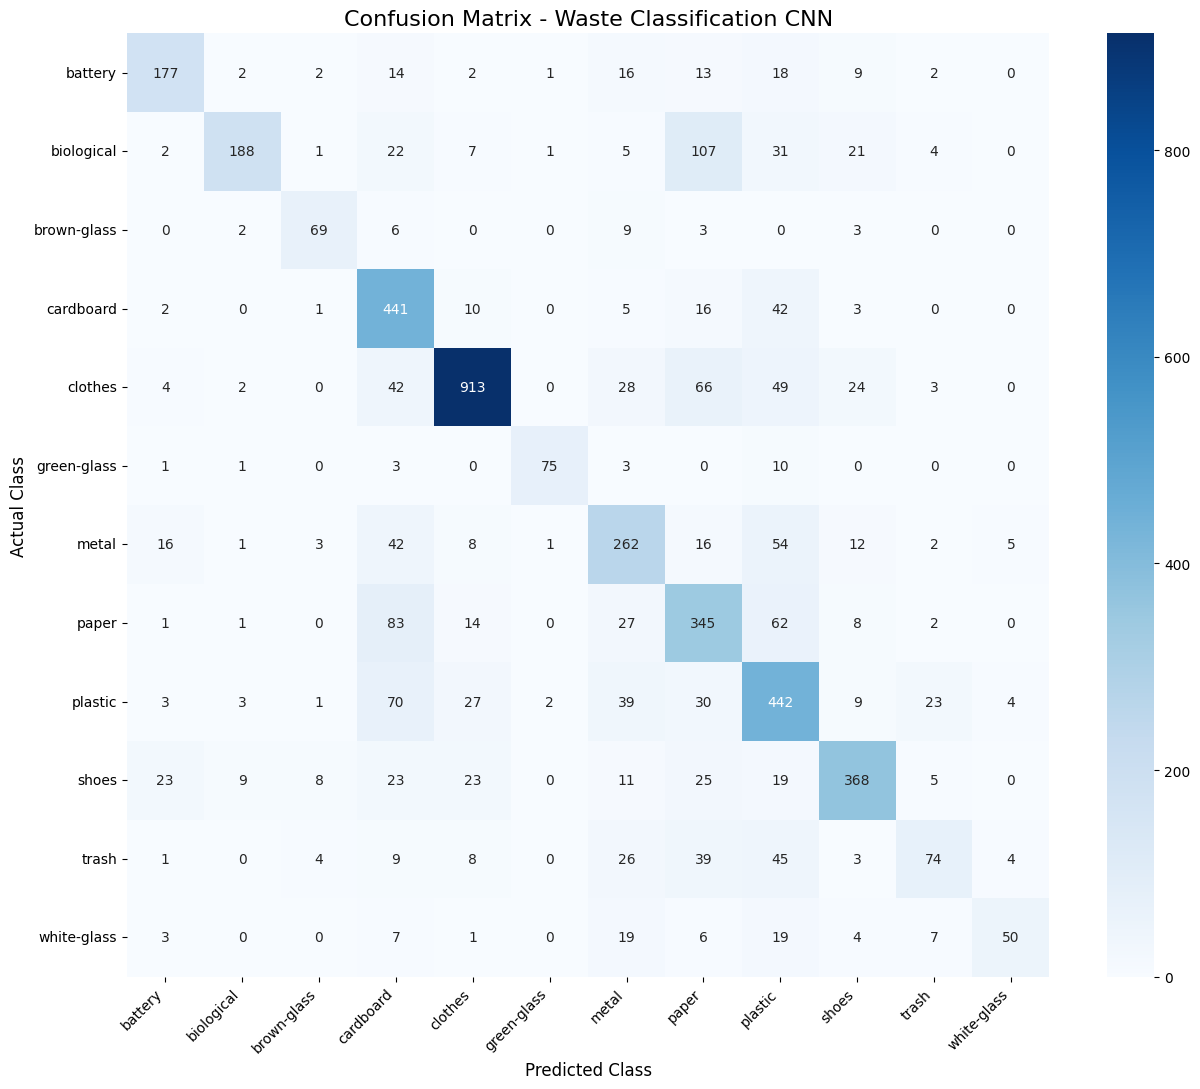


CLASSIFICATION REPORT
              precision    recall  f1-score   support

     battery       0.76      0.69      0.72       256
  biological       0.90      0.48      0.63       389
 brown-glass       0.78      0.75      0.76        92
   cardboard       0.58      0.85      0.69       520
     clothes       0.90      0.81      0.85      1131
 green-glass       0.94      0.81      0.87        93
       metal       0.58      0.62      0.60       422
       paper       0.52      0.64      0.57       543
     plastic       0.56      0.68      0.61       653
       shoes       0.79      0.72      0.75       514
       trash       0.61      0.35      0.44       213
 white-glass       0.79      0.43      0.56       116

    accuracy                           0.69      4942
   macro avg       0.73      0.65      0.67      4942
weighted avg       0.72      0.69      0.69      4942



In [ ]:
import tensorflow as tf
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ============================================================
# 1. LOAD MODEL
# ============================================================

model = tf.keras.models.load_model("/content/cnn_model.keras")

# ============================================================
# 2. CLASS NAMES
# ============================================================

with open("/content/class_names.json", "r") as f:
    class_data = json.load(f)

if isinstance(class_data, dict):
    class_names = [
        name
        for name, index in sorted(
            class_data.items(),
            key=lambda x: x[1]
        )
    ]
else:
    class_names = class_data

print("Classes:", class_names)

# ============================================================
# 3. TEST DATA
# ============================================================

test_dir = "/content/Waste_Dataset_Split/test"

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

# ============================================================
# 4. PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

predictions = model.predict(
    test_generator,
    verbose=1
)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

# ============================================================
# 6. PLOT
# ============================================================

plt.figure(figsize=(13, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Confusion Matrix - Waste Classification CNN",
    fontsize=16
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

# ============================================================
# 7. CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=2
    )
)

In [ ]:
!pkill -f streamlit || true

!streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

^C


In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-usc1b1-1c0v0vzmhd5cz-b.us-central1-1.prod.colab.dev


In [ ]:
!tail -50 /content/streamlit.log

/bin/bash: line 1: streamlit: command not found


In [18]:
import streamlit
print("Streamlit version:", streamlit.__version__)

Streamlit version: 1.65.0


In [17]:
!python -m pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 49.3 MB/s eta 0:00:00


In [19]:
!pkill -f streamlit || true

!python -m streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

^C


In [20]:
!tail -30 /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/app.py


In [21]:
import os

print("Model:", os.path.exists("/content/cnn_model.keras"))
print("Classes:", os.path.exists("/content/class_names.json"))

Model: False
Classes: False


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
import shutil
import os

drive_model = "/content/drive/MyDrive/Waste_Classification/cnn_model.keras"
local_model = "/content/cnn_model.keras"

shutil.copy2(drive_model, local_model)

print("Model restored:", os.path.exists(local_model))

Model restored: True


In [24]:
import json

class_mapping = {
    "battery": 0,
    "biological": 1,
    "brown-glass": 2,
    "cardboard": 3,
    "clothes": 4,
    "green-glass": 5,
    "metal": 6,
    "paper": 7,
    "plastic": 8,
    "shoes": 9,
    "trash": 10,
    "white-glass": 11
}

with open("/content/class_names.json", "w") as f:
    json.dump(class_mapping, f, indent=4)

print("Classes restored!")

Classes restored!


In [25]:
import os

print("Model:", os.path.exists("/content/cnn_model.keras"))
print("Classes:", os.path.exists("/content/class_names.json"))

Model: True
Classes: True


In [26]:
!pkill -f streamlit || true

!python -m streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

^C


In [27]:
!tail -20 /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/app.py


In [29]:
import os

print("App:", os.path.exists("/content/app.py"))

App: True


In [30]:
!pkill -f streamlit || true

!python -m streamlit run /content/app.py \
--server.port 8501 \
--server.address 0.0.0.0 \
--server.headless true \
--server.enableCORS false \
--server.enableXsrfProtection false \
> /content/streamlit.log 2>&1 &

^C


In [31]:
!tail -20 /content/streamlit.log



2026-10-09 05:20:46.173 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.114.129.250:8501



In [32]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-usc1b1-1c0v0vzmhd5cz-b.us-central1-1.prod.colab.dev
